# 03 · Forecasting at Scale — 500 Store-Item Series
**Author: Anurag Moyal**

Notebook 02 forecast one aggregate series. Real replenishment decisions are made **per store and per item**, i.e. 500 series
that are far noisier (a single item in a single store sells ~50 units/day). Fitting 500 separate ARIMA models is slow and ignores the
fact that all series share the same seasonality, so here we compare:

| Model | Idea |
|---|---|
| Naive (28-day mean) | benchmark |
| Seasonal average | mean of the same weekday over the last 8 weeks |
| Seasonal naive YoY × growth | last year's same weekday × recent growth |
| ETS per series | 500 separate Holt-Winters models (weekly seasonality) |
| **Global LightGBM** | **one** gradient-boosting model trained on all 500 series, direct multi-horizon (day 1…90), features built only from data known at the forecast origin |

**Backtest:** three non-overlapping 90-day windows (rolling origin). **Headline metrics:** WAPE and MAPE at the item level, plus accuracy after
rolling forecasts up to store and total level (bottom-up).

In [1]:
import time, warnings, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from joblib import Parallel, delayed
from statsmodels.tsa.holtwinters import ExponentialSmoothing

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from forecast_utils import metrics, rolling_origins, build_rows, FEATURES

warnings.filterwarnings("ignore")
FIG, REP = ROOT / "reports/figures", ROOT / "reports"
sns.set_theme(style="whitegrid")
BLUE, ORANGE, GREEN, RED, GREY, PURPLE = "#2F5D8A", "#E08A2E", "#2E8B57", "#C0392B", "#8A8F98", "#7A6FAC"
def save(n): plt.tight_layout(); plt.savefig(FIG / f"{n}.png", dpi=150, bbox_inches="tight"); plt.show()

df = pd.read_csv(ROOT / "data/raw/train.csv", parse_dates=["date"])
P = df.pivot_table(index="date", columns=["store", "item"], values="sales")
dates, S = P.index, P.values.astype(float)
store = np.array([c[0] - 1 for c in P.columns]); item = np.array([c[1] - 1 for c in P.columns])
T, NS = S.shape; H = 90
folds = rolling_origins(dates, H, 3)
print(f"{NS} series × {T:,} days · horizon {H} days")
for i, (o, a, b) in enumerate(folds, 1): print(f"Fold {i}: origin {dates[o].date()} · test {dates[a].date()} → {dates[b].date()}")

500 series × 1,826 days · horizon 90 days
Fold 1: origin 2017-04-05 · test 2017-04-06 → 2017-07-04
Fold 2: origin 2017-07-04 · test 2017-07-05 → 2017-10-02
Fold 3: origin 2017-10-02 · test 2017-10-03 → 2017-12-31


## 1. Models

In [2]:
def ets_one(x, h):
    try:
        m = ExponentialSmoothing(x[-730:], trend=None, seasonal="add", seasonal_periods=7, initialization_method="estimated").fit()
        return m.forecast(h)
    except Exception:
        return np.full(h, x[-28:].mean())

GL = dict(n_estimators=600, learning_rate=0.05, num_leaves=63, min_child_samples=100, subsample=.8, subsample_freq=1, colsample_bytree=.8,
          verbose=-1, n_jobs=-1, random_state=42)
def fit_lgbm(origin):
    rows = build_rows(S, dates, range(372, origin + 1, 28), H, cutoff=origin, store=store, item=item)   # only targets <= origin
    mdl = lgb.LGBMRegressor(**GL).fit(rows[FEATURES], rows.y / (rows.m91 + 1), categorical_feature=["store", "item"])
    return mdl, len(rows)

def forecast_all(origin):
    """All five models at one origin -> dict name -> array (H, NS)."""
    te = build_rows(S, dates, [origin], H, store=store, item=item, with_target=False)
    shape = lambda v: np.asarray(v).reshape(H, NS)
    out = {"Naive (28-day mean)": shape(te.m28), "Seasonal average (8 wks)": shape(te.dow_mean8),
           "Seasonal naive YoY×growth": shape(te.yoy * te.growth)}
    t0 = time.time(); ets = Parallel(n_jobs=-1)(delayed(ets_one)(S[: origin + 1, j], H) for j in range(NS)); out["ETS per series"] = np.column_stack(ets); t_ets = time.time() - t0
    t0 = time.time(); mdl, n = fit_lgbm(origin); out["Global LightGBM"] = shape(mdl.predict(te[FEATURES]) * (te.m91 + 1)); t_lgb = time.time() - t0
    return out, mdl, dict(ets=t_ets, lgbm=t_lgb, rows=n)

MODELS = ["Naive (28-day mean)", "Seasonal average (8 wks)", "Seasonal naive YoY×growth", "ETS per series", "Global LightGBM"]

## 2. Rolling-origin backtest

In [3]:
F, A, rows, extra, models_fit = [], [], [], [], []
for k, (o, a, b) in enumerate(folds, 1):
    out, mdl, info = forecast_all(o); act = S[a: b + 1]; F.append(out); A.append(act); models_fit.append(mdl); extra.append(info)
    for m in MODELS:
        rows.append(dict(fold=k, model=m, level="Store-item (500)", **metrics(act, out[m])))
        st = np.column_stack([out[m][:, store == s].sum(1) for s in range(10)]); sa = np.column_stack([act[:, store == s].sum(1) for s in range(10)])
        rows.append(dict(fold=k, model=m, level="Store (10)", **metrics(sa, st)))
        rows.append(dict(fold=k, model=m, level="Total (1)", **metrics(act.sum(1), out[m].sum(1))))
    print(f"fold {k}: LightGBM trained on {info['rows']:,} rows in {info['lgbm']:.0f}s · ETS×500 in {info['ets']:.0f}s")
R = pd.DataFrame(rows)
item_sum = R[R.level == "Store-item (500)"].groupby("model")[["MAPE", "RMSE", "WAPE", "MAE", "Bias"]].mean().loc[MODELS]
item_sum.round(2).style.format("{:.2f}").background_gradient(cmap="Greens_r", subset=["MAPE", "RMSE", "WAPE"])

fold 1: LightGBM trained on 1,852,500 rows in 136s · ETS×500 in 24s


fold 2: LightGBM trained on 1,996,500 rows in 81s · ETS×500 in 13s


fold 3: LightGBM trained on 2,140,500 rows in 93s · ETS×500 in 9s


,MAPE,RMSE,WAPE,MAE,Bias
model,,,,,
Naive (28-day mean),22.21,16.32,19.74,12.38,0.09
Seasonal average (8 wks),21.72,15.70,19.58,12.27,-1.43
Seasonal naive YoY×growth,16.65,11.51,14.15,8.88,-0.36
ETS per series,18.60,13.18,16.11,10.07,1.97
Global LightGBM,12.06,8.15,10.04,6.30,0.98


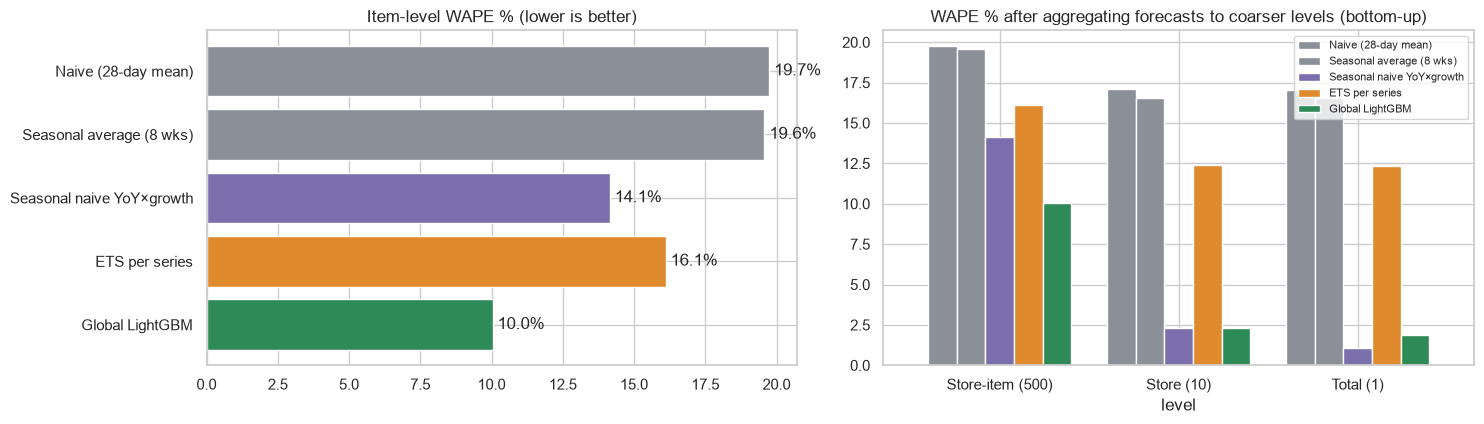

level,Store-item (500),Store (10),Total (1)
model,,,
Naive (28-day mean),19.74,17.11,17.06
Seasonal average (8 wks),19.58,16.57,16.54
Seasonal naive YoY×growth,14.15,2.32,1.07
ETS per series,16.11,12.38,12.33
Global LightGBM,10.04,2.28,1.90


In [4]:
lvl = R.pivot_table(index="model", columns="level", values="WAPE", aggfunc="mean").loc[MODELS][["Store-item (500)", "Store (10)", "Total (1)"]]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
cols = [GREY, GREY, PURPLE, ORANGE, GREEN]
ax[0].barh(MODELS[::-1], item_sum.WAPE.values[::-1], color=cols[::-1]); ax[0].set_title("Item-level WAPE % (lower is better)")
for i, v in enumerate(item_sum.WAPE.values[::-1]): ax[0].text(v, i, f" {v:.1f}%", va="center")
lvl.T.plot.bar(ax=ax[1], color=cols, width=.8, rot=0); ax[1].set_title("WAPE % after aggregating forecasts to coarser levels (bottom-up)"); ax[1].legend(fontsize=8)
save("12_store_item_comparison")
lvl.round(2)

**Aggregation effect.** Random item-level noise partly cancels when forecasts are summed, so the *same* model looks far more accurate at store and
total level. Always state the level at which accuracy is quoted.

## 3. Where does the model win and lose?

LightGBM beats the YoY rule on 100% of the 500 series (final window).


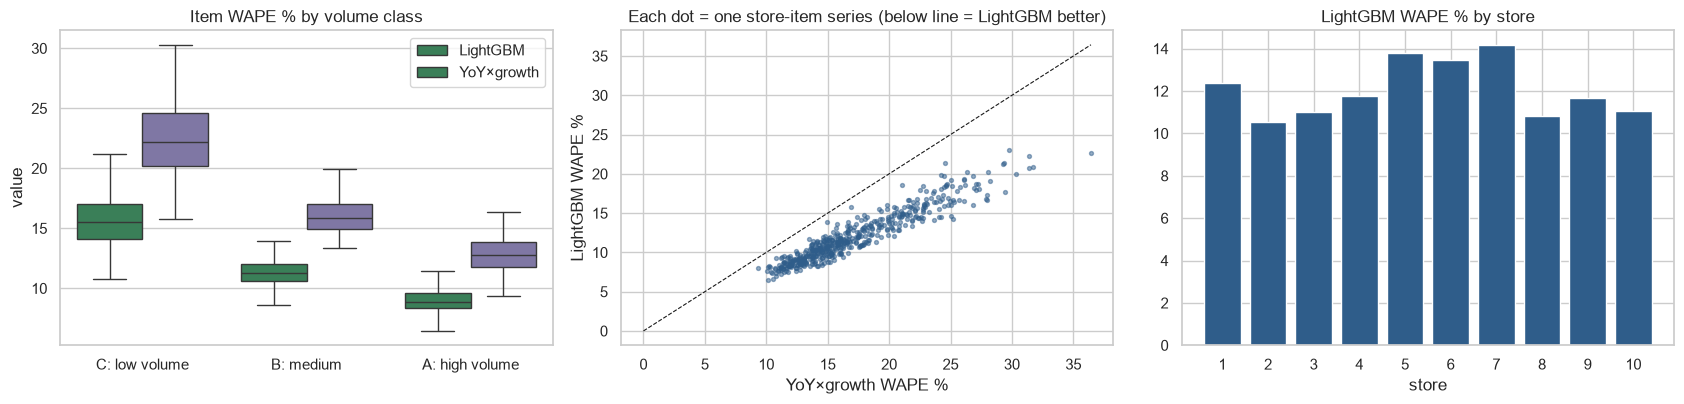

In [5]:
fold = len(folds) - 1                                        # final window
act, fl = A[fold], F[fold]["Global LightGBM"]
fy = F[fold]["Seasonal naive YoY×growth"]
vol = S[: folds[fold][0] + 1][-91:].mean(0)
cls = pd.qcut(vol, 3, labels=["C: low volume", "B: medium", "A: high volume"])
per = pd.DataFrame({"series": np.arange(NS), "store": store + 1, "item": item + 1, "volume": vol, "cls": cls,
                    "wape_lgb": np.abs(fl - act).sum(0) / act.sum(0) * 100, "wape_yoy": np.abs(fy - act).sum(0) / act.sum(0) * 100})
win = (per.wape_lgb < per.wape_yoy).mean() * 100
print(f"LightGBM beats the YoY rule on {win:.0f}% of the 500 series (final window).")
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
sns.boxplot(data=per.melt(id_vars="cls", value_vars=["wape_lgb", "wape_yoy"]), x="cls", y="value", hue="variable", ax=ax[0], palette=[GREEN, PURPLE], showfliers=False)
ax[0].set_title("Item WAPE % by volume class"); ax[0].set_xlabel(""); ax[0].legend(title="", labels=["LightGBM", "YoY×growth"])
ax[1].scatter(per.wape_yoy, per.wape_lgb, s=8, alpha=.5, color=BLUE); lim = [0, max(per.wape_yoy.max(), per.wape_lgb.max())]
ax[1].plot(lim, lim, "k--", lw=.8); ax[1].set_xlabel("YoY×growth WAPE %"); ax[1].set_ylabel("LightGBM WAPE %"); ax[1].set_title("Each dot = one store-item series (below line = LightGBM better)")
sw = per.groupby("store").wape_lgb.mean(); ax[2].bar(sw.index.astype(str), sw.values, color=BLUE); ax[2].set_title("LightGBM WAPE % by store"); ax[2].set_xlabel("store")
save("13_where_model_wins")

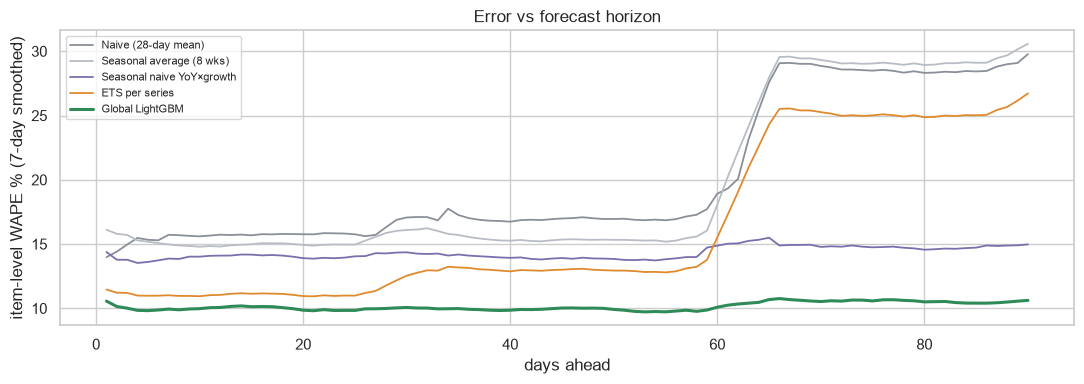

In [6]:
hz = np.arange(1, H + 1)
fig, ax = plt.subplots(figsize=(11, 4))
for m, c in zip(MODELS, [GREY, "#B8BCC4", PURPLE, ORANGE, GREEN]):
    w = np.mean([np.abs(F[i][m] - A[i]).sum(1) / A[i].sum(1) * 100 for i in range(len(folds))], axis=0)
    ax.plot(hz, pd.Series(w).rolling(7, min_periods=1).mean(), label=m, color=c, lw=2.2 if m == "Global LightGBM" else 1.3)
ax.set_xlabel("days ahead"); ax.set_ylabel("item-level WAPE % (7-day smoothed)"); ax.set_title("Error vs forecast horizon"); ax.legend(fontsize=8)
save("14_error_by_horizon_items")

## 4. What does the LightGBM model use? (feature importance)

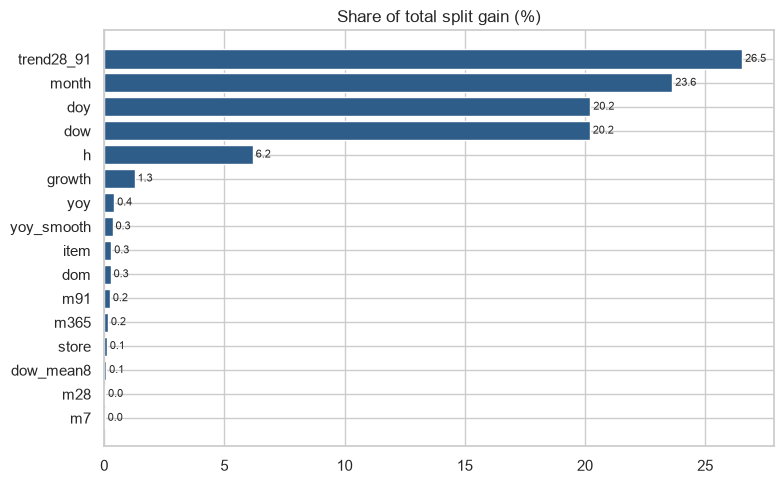

Top drivers: trend28_91 (27%), month (24%), doy (20%), dow (20%)


In [7]:
imp = pd.Series(models_fit[-1].booster_.feature_importance("gain"), index=FEATURES).sort_values()
imp = imp / imp.sum() * 100
fig, ax = plt.subplots(figsize=(8, 5)); ax.barh(imp.index, imp.values, color=BLUE); ax.set_title("Share of total split gain (%)")
for i, v in enumerate(imp.values): ax.text(v, i, f" {v:.1f}", va="center", fontsize=8)
save("15_feature_importance")
print("Top drivers:", ", ".join(f"{k} ({v:.0f}%)" for k, v in imp.sort_values(ascending=False).head(4).items()))

## 5. Business impact: safety stock
Standard inventory rule: **safety stock = z × σ(forecast error) × √(lead time)**. With a 95 % service level (z = 1.645) and a 7-day replenishment
lead time, a more accurate forecast directly means less cash tied up in buffer stock. σ is estimated per series from the backtest errors.
(Approximation: it assumes errors are independent from day to day, which is rarely exact.)

In [8]:
Z, LT = 1.645, 7
def safety_units(m):
    err = np.concatenate([F[i][m] - A[i] for i in range(len(folds))])        # (3H, NS)
    return (Z * err.std(axis=0) * np.sqrt(LT)).sum()
ss = pd.Series({m: safety_units(m) for m in MODELS}); base = ss["Seasonal naive YoY×growth"]
tab = pd.DataFrame({"safety stock (units)": ss, "vs YoY rule": (ss / base - 1) * 100, "vs naive": (ss / ss["Naive (28-day mean)"] - 1) * 100})
print(f"Safety stock (all 500 series, 95% service, {LT}-day lead time):"); tab.round(1).style.format({"safety stock (units)": "{:,.0f}", "vs YoY rule": "{:+.1f}%", "vs naive": "{:+.1f}%"})

Safety stock (all 500 series, 95% service, 7-day lead time):


,safety stock (units),vs YoY rule,vs naive
Naive (28-day mean),"33,174",+36.6%,+0.0%
Seasonal average (8 wks),"32,567",+34.1%,-1.8%
Seasonal naive YoY×growth,"24,288",+0.0%,-26.8%
ETS per series,"26,776",+10.2%,-19.3%
Global LightGBM,"17,143",-29.4%,-48.3%


## 6. Production forecast: the next 90 days (Jan–Mar 2018)
The winning model is retrained on **all** available data and used for the genuinely unseen period 2018-01-01 → 2018-03-31.

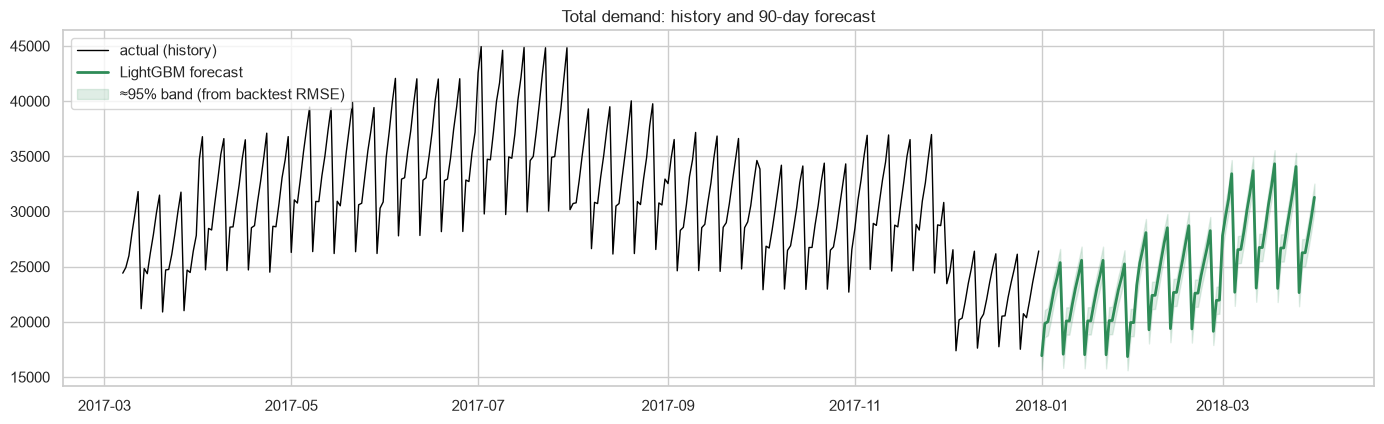

Forecast file: reports/forecast_2018Q1_store_item.csv  (45,000 rows)  ·  total forecast 90 days = 2,225,872 units


In [9]:
mdl_full, nrows = fit_lgbm(T - 1)
fut = build_rows(S, dates, [T - 1], H, store=store, item=item, with_target=False)
pred = mdl_full.predict(fut[FEATURES]) * (fut.m91 + 1)
fdates = pd.date_range(dates[-1] + pd.Timedelta(days=1), periods=H)
out = pd.DataFrame({"date": fdates[fut.h.values - 1], "store": store[fut.series.values] + 1, "item": item[fut.series.values] + 1,
                    "forecast": np.round(pred.values, 1)})
out.to_csv(REP / "forecast_2018Q1_store_item.csv", index=False)
tf = out.groupby("date").forecast.sum()
band = Z * np.sqrt(np.mean([(F[i]["Global LightGBM"].sum(1) - A[i].sum(1)) ** 2 for i in range(len(folds))]))
fig, ax = plt.subplots(figsize=(14, 4.4))
tot = pd.Series(S.sum(1), index=dates)
ax.plot(tot.index[-300:], tot.values[-300:], color="black", lw=1, label="actual (history)")
ax.plot(tf.index, tf.values, color=GREEN, lw=2, label="LightGBM forecast"); ax.fill_between(tf.index, tf.values - band, tf.values + band, color=GREEN, alpha=.15, label="≈95% band (from backtest RMSE)")
ax.set_title("Total demand: history and 90-day forecast"); ax.legend(loc="upper left")
save("16_production_forecast")
print(f"Forecast file: reports/forecast_2018Q1_store_item.csv  ({len(out):,} rows)  ·  total forecast 90 days = {tf.sum():,.0f} units")

## 7. Conclusions

In [10]:
b = item_sum.loc["Global LightGBM"]; y_ = item_sum.loc["Seasonal naive YoY×growth"]; n_ = item_sum.loc["Naive (28-day mean)"]; e_ = item_sum.loc["ETS per series"]
print(f"""Item level (500 series, 3 backtest windows):
  Global LightGBM  : WAPE {b.WAPE:.1f}% · MAPE {b.MAPE:.1f}% · RMSE {b.RMSE:.2f} units/day
  YoY×growth rule  : WAPE {y_.WAPE:.1f}% · MAPE {y_.MAPE:.1f}% · RMSE {y_.RMSE:.2f}
  ETS per series   : WAPE {e_.WAPE:.1f}% · MAPE {e_.MAPE:.1f}% · RMSE {e_.RMSE:.2f}
  Naive 28-day mean: WAPE {n_.WAPE:.1f}% · MAPE {n_.MAPE:.1f}% · RMSE {n_.RMSE:.2f}
→ LightGBM cuts WAPE by {(1 - b.WAPE / y_.WAPE) * 100:.0f}% vs the YoY rule and {(1 - b.WAPE / n_.WAPE) * 100:.0f}% vs naive; it wins on {win:.0f}% of series.
Aggregation cancels noise, and the simple YoY rule closes the gap: WAPE LightGBM vs YoY rule = {lvl.loc['Global LightGBM', 'Store (10)']:.1f}% vs {lvl.loc['Seasonal naive YoY×growth', 'Store (10)']:.1f}% at store level,
  {lvl.loc['Global LightGBM', 'Total (1)']:.1f}% vs {lvl.loc['Seasonal naive YoY×growth', 'Total (1)']:.1f}% at total level — the ML advantage is largest where the data is noisiest (item level).
Safety stock needed: {tab.loc['Global LightGBM', 'vs YoY rule']:+.0f}% vs the YoY rule, {tab.loc['Global LightGBM', 'vs naive']:+.0f}% vs naive.""")
R.round(3).to_csv(REP / "results_store_item_levels.csv", index=False)
tab.round(2).to_csv(REP / "results_safety_stock.csv")

Item level (500 series, 3 backtest windows):
  Global LightGBM  : WAPE 10.0% · MAPE 12.1% · RMSE 8.15 units/day
  YoY×growth rule  : WAPE 14.1% · MAPE 16.7% · RMSE 11.51
  ETS per series   : WAPE 16.1% · MAPE 18.6% · RMSE 13.18
  Naive 28-day mean: WAPE 19.7% · MAPE 22.2% · RMSE 16.32
→ LightGBM cuts WAPE by 29% vs the YoY rule and 49% vs naive; it wins on 100% of series.
Aggregation cancels noise, and the simple YoY rule closes the gap: WAPE LightGBM vs YoY rule = 2.3% vs 2.3% at store level,
  1.9% vs 1.1% at total level — the ML advantage is largest where the data is noisiest (item level).
Safety stock needed: -29% vs the YoY rule, -48% vs naive.
